# 00 · Machine interface: the abstract layer every application uses

Every GUI talks to a machine only through an interface object (`InterfaceCLEAR`, `InterfaceATF2_Ext_RFTrack`, …). The same GUI therefore runs on the real machine and on its RF-Track simulation. The only thing that needs to be the same is a data format.

The tutorials are running on a simple beamline with 6 correctors and 5 BPMs.

**This way operators can develop their own applications and ideas, first test it on the simulated machine to inspect if the logic works, and then apply to the real machine. Application logic always stays the same, and the operator doesn't need to know anything else than a desired value and a device name, e.g. Corrector3, instead of the full address in the system.**

The interface also serves as a base, in case of a need to quickly write test scripts, e.g. to measure dispersion on the machine, or any other quantity. It can be done with about 5 lines of code.


## Some interface methods

| Method | Returns / does |
|---|---|
| `get_bpms(names)` | `{"names", "x", "y", "tmit"}`; `x`, `y` have one row per shot and one column per BPM |
| `get_correctors(names)` | `{"names", "bdes", "bact"}`: set point and readback |
| `set_correctors(names, values)` | sets absolute values; returns `False` if a readback is not confirmed after the interface's retries, and the GUIs then stop |
| `get_state()` | a `State` object (current state of the machine): correctors, BPM shots, sequence, plane names, beam settings, timestamp |
| `change_energy()` / `reset_energy()`, `change_intensity()` / `reset_intensity()` | beam changes used for DFS and WFS |
| `nsamples` | number of BPM shots per acquisition (the **BPM samples** field in the GUIs) |

**and more...**

Units depend on the machine. They can be specified in **interface_setup.py** file for each machine.

In a drift, a kick $\Delta\theta_j$ at $s_j$ moves a downstream BPM by
$$\Delta x_i=(s_i-s_j)\,\Delta\theta_j ,$$
For both planes together
$$\mathbf b=\mathbf b_0+R\,\mathbf c+\mathbf n ,$$
with BPM readings $\mathbf b$, corrector settings $\mathbf c$, a static orbit $\mathbf b_0$ and noise $\mathbf n$. Rows of $R$ are BPMs, columns are correctors.

## Short interface recipes

- [Measure dispersion](00a_DispersionMeasurement.ipynb): compare the orbit at two energies.
- [Get a screen image](00b_GetScreenImage.ipynb): display the beam and read its position and size.
- [Read the orbit](00c_ReadOrbit.ipynb): average BPM shots and plot the uncertainty.
- [Save and load a measurement](00d_SaveLoadState.ipynb): analyse a recorded snapshot offline.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Beamline

machine = Beamline(seed=42)
initial = machine.get_correctors()['bdes'].copy()
state = machine.get_state()
orbit = state.get_orbit()
print(machine.get_name())
print('Correctors:', state.get_correctors()['names'])
print('BPM shots x BPMs:', state.get_bpms()['x'].shape)

Tutorial linear beamline
Correctors: ['HC1', 'HC2', 'HC3', 'VC1', 'VC2', 'VC3']
BPM shots x BPMs: (32, 5)


## Average the shots

`State.get_orbit()` turns the shots into one orbit. For each BPM it

1. sets a shot to NaN when $|x|>10\,\mathrm{median}(|x|)$ (outlier rejection),
2. returns the mean $\bar x$ and the shot-to-shot standard deviation $s_x$ (`stdx`),
3. flags a BPM as faulty when its mean is NaN or exactly $(0,0)$.

The standard deviation describes the beam jitter and BPM noise; it does not shrink with more shots. The uncertainty of the **mean** does:
$$u(\bar x)=\frac{s_x}{\sqrt N}.$$

### Choosing BPM samples

To resolve an orbit change $\Delta x$ you need $u(\bar x)\ll\Delta x$. For a required uncertainty $u$,
$$N\approx\left(\frac{s_x}{u}\right)^2 .$$
Example: with 20 µm jitter and a 2 µm requirement you need $N\approx100$ shots. Halving the uncertainty costs four times the measurement time.

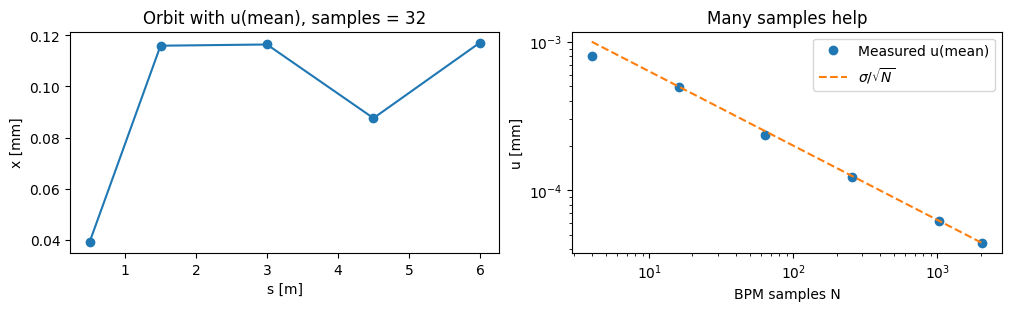

In [2]:
samples = [4, 16, 64, 256, 1024, 2048]
u_mean = []
for n in samples:
    machine.nsamples = n
    o = machine.get_state().get_orbit()
    u_mean.append(np.mean(o['stdx'] / np.sqrt(o['nshots'])))
machine.nsamples = 32

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].errorbar(machine.s_bpms, orbit['x'], yerr=orbit['stdx'] / np.sqrt(orbit['nshots']), fmt='o-')
axes[0].set(xlabel='s [m]', ylabel='x [mm]', title='Orbit with u(mean), samples = 32')
axes[1].loglog(samples, u_mean, 'o', label='Measured u(mean)')
axes[1].loglog(samples, machine.noise_mm / np.sqrt(samples), '--', label=r'$\sigma/\sqrt{N}$')
axes[1].set(xlabel='BPM samples N', ylabel='u [mm]', title='Many samples help')
axes[1].legend()
plt.show()

## Change one corrector and always restore it

Every application follows the same pattern: remember the initial settings, change them, measure, and restore them in a `finally` block so that an error cannot leave the machine in a changed state. `bdes` is the requested (desired) value and `bact` the readback (actual); the applications use the readback when they compute a response.

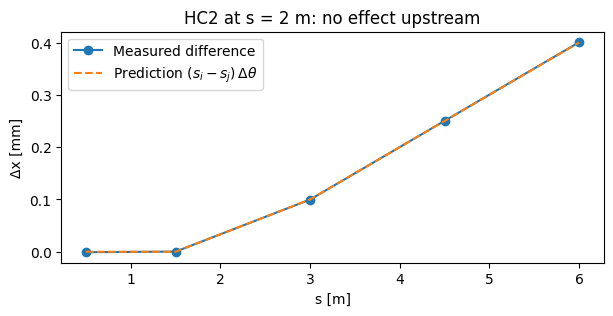

Restored: True


In [3]:
try:
    machine.set_correctors(['HC2'], [0.10])
    changed = machine.get_state().get_orbit()
finally:
    machine.set_correctors(machine.correctors, initial)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(machine.s_bpms, changed['x'] - orbit['x'], 'o-', label='Measured difference')
ax.plot(machine.s_bpms, 0.10 * machine.R[:5, 1], '--', label=r'Prediction $(s_i-s_j)\,\Delta\theta$')
ax.set(xlabel='s [m]', ylabel='Δx [mm]', title='HC2 at s = 2 m: no effect upstream')
ax.legend()
plt.show()
print('Restored:', np.array_equal(machine.settings, initial))

## Everything an interface can do

The table above shows only the methods used in the next tutorials. `AbstractMachineInterface` defines the full set. *Required* methods (`@abstractmethod`) must be implemented by every interface. *Optional* ones have a default: for example `get_quadrupoles()` and `get_sextupoles()` return empty lists and `set_quadrupoles()` raises `NotImplementedError`, so an interface overrides them only when the machine has these devices.

In [4]:
import inspect
from machine_interfaces.Interfaces.AbstractMachineInterface import AbstractMachineInterface

for name, method in inspect.getmembers(AbstractMachineInterface, inspect.isfunction):
    if not name.startswith('_'):
        kind = 'required' if name in AbstractMachineInterface.__abstractmethods__ else 'optional'
        print(f'{kind:9s}{name}{inspect.signature(method)}')

required change_energy(self)
required change_intensity(self)
optional get_beam_evolution(self, quad_name, screens, quad_setting, quad_value_unit, beam_parameters)
optional get_beam_settings(self)
required get_bpms(self, names=None)
required get_correctors(self, names=None)
required get_icts(self, names=None)
required get_name(self)
optional get_quadrupoles(self, names=None)
optional get_screens(self, names=None)
required get_sequence(self)
optional get_sextupoles(self, names=None)
optional get_state(self)
optional get_target_dispersion(self, names=None)
optional match_screen_name(self, name, candidates)
required reset_energy(self)
required reset_intensity(self)
optional restore_beam_settings(self, settings)
optional restore_correctors_state(self, state)
optional restore_quadrupoles_state(self, state)
optional restore_sextupoles_state(self, state)
optional scale_quadrupoles(self, scale=None)
required set_correctors(self, names, values)
optional set_quadrupoles(self, names, values)
optio

## A real interface example: CLEAR in RF-Track

We demonstrate what methods already exist in CLEAR RF-Track (simulated machine) interface.

Besides the common methods it has its own, e.g. the current ↔ gradient conversion of quadrupoles (`get_grad`, `get_current_from_grad`) and the transfer matrices and scan predictions used by Emittance Measurement (`get_R_matrix_scan`, `predict_emittance_scan_response`). The attributes hold the simulation settings, e.g. `nsamples`, `jitter` and `population`; here `nparticles` is raised from the default 1000 to get a smoother screen image.

This part needs RF-Track and the CLEAR simulation backend in the tutorial environment. From the directory containing the repositories:

```bash
python -m pip install rf-track cpymad
python -m pip install --no-deps -e machine-interfaces/backends/clear
```

In [5]:
from machine_interfaces_clear.InterfaceCLEAR_RFTrack import InterfaceCLEAR_RFTrack

clear = InterfaceCLEAR_RFTrack(nsamples=3, nparticles=50000)
common = dict(inspect.getmembers(AbstractMachineInterface, inspect.isfunction))
specific = [name for name in dir(clear) if not name.startswith('_') and callable(getattr(clear, name)) and name not in common]
print('Not in AbstractMachineInterface:', ', '.join(specific))
print('Settings:', {name: value for name, value in vars(clear).items() if not name.startswith('_') and np.isscalar(value)})


RF-Track, version 2.7.3

Copyright (C) 2016-2026 CERN, Geneva, Switzerland. All rights reserved.

Author and contact:
 Andrea Latina <andrea.latina@cern.ch>
 BE-ABP Group
 CERN
 CH-1211 GENEVA 23
 SWITZERLAND

This software is distributed under a CERN proprietary software
license in the hope that it will be useful, but WITHOUT ANY WARRANTY;
not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

See the COPYRIGHT and LICENSE files at the top-level directory of
the RF-Track download area: https://gitlab.cern.ch/rf-track

RF-Track was compiled with GSL-2.8 and fftw-3.3.11



[RF-Track] Could not check for updates.


Not in AbstractMachineInterface: get_ITF, get_R_matrix_scan, get_beam_factors, get_current_from_grad, get_elements_indices, get_elements_position, get_emittance_at_screens, get_grad, get_hcorrectors_names, get_phase_space_transport_to_screens, get_vcorrectors_names, log, predict_emittance_scan_response, predict_emittance_scan_response_full, vary_correctors
Settings: {'sigmaCut': 4.0, 'Pref': 198, 'Q': -1, 'population': 1872452722.338229, 'jitter': 0.01, 'nsamples': 3, 'nparticles': 50000, 'electronmass': 0.51099895, 'is_simulation': True, 'start': 'CA.DHG0130', 'end': 'CLEARLINE$END', 'dfs_test_energy': 0.9, 'wfs_test_charge': 0.9, 'freq': 2997000000.0, 'nr_quad': 11, 'Lquad': 0.226, 'nominal_K': 0.7752883624676146, 'machine_name': 'CLEAR', 'chosen_ict': 'CA.BPM0890', 'invert_bpm': True, 'quadrupole_scaling_factor': 0.5}


### Read every device type

Every `get_*` method returns a dictionary with `names` and one array per quantity, in the order of `names`. Quadrupoles and sextupoles have set points and readbacks like correctors, ICTs give the bunch charge, and screens give the beam centroid, sizes and the image.

In [6]:
devices = {'Correctors': clear.get_correctors(), 'BPMs': clear.get_bpms(), 'ICTs': clear.get_icts(),
           'Quadrupoles': clear.get_quadrupoles(), 'Sextupoles': clear.get_sextupoles(), 'Screens': clear.get_screens()}
for label, data in devices.items():
    print(f"{label:12s}{len(data['names']):3d} devices   keys: {', '.join(data)}")

quadrupoles, icts, screens = devices['Quadrupoles'], devices['ICTs'], devices['Screens']
print('\nSequence:', len(clear.get_sequence()), 'elements, starting with', clear.get_sequence()[:3])
print(f"Quadrupole currents [{quadrupoles['value_unit']}]:", dict(zip(quadrupoles['names'], np.round(quadrupoles['bdes'], 1).tolist())))
print('ICT charge:', dict(zip(icts['names'], icts['charge'].tolist())))
print('Beam settings:', clear.get_beam_settings())

Reading bpms...
Reading ict's...
Correctors   12 devices   keys: names, bdes, bact
BPMs          5 devices   keys: names, x, y, tmit
ICTs          5 devices   keys: names, charge
Quadrupoles  11 devices   keys: names, bdes, bact, value_unit
Sextupoles    0 devices   keys: names, bdes, bact
Screens       7 devices   keys: names, hpixel, vpixel, x, y, sigx, sigy, sigxy, sum, hedges, vedges, images, S

Sequence: 101 elements, starting with ['CA.DHG0130', 'GAP_DHG0130_DHG0225', 'CA.DHG0225']
Quadrupole currents [A]: {'CA.QFD0350': 47.5, 'CA.QDD0355': 86.5, 'CA.QFD0360': 59.0, 'CA.QFD0510': 44.0, 'CA.QDD0515': 71.8, 'CA.QFD0520': 38.8, 'CA.QFD0760': 61.0, 'CA.QDD0765': 98.0, 'CA.QFD0770': 53.0, 'CA.QDD0870': 0.0, 'CA.QFD0880': 0.0}
ICT charge: {'CA.BPM0530': -1872452722.3374653, 'CA.BPM0595': -1872452722.3374653, 'CA.BPM0690': -1872452722.3374653, 'CA.BPM0820': -1872452722.3374653, 'CA.BPM0890': -1872452722.3374653}
Beam settings: {'simulation': {'beam_mode': 'nominal', 'dfs_energy_scale': 

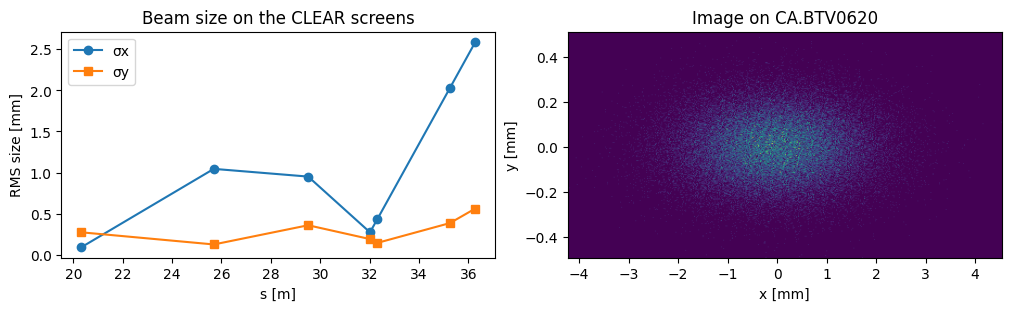

In [7]:
i = screens['names'].index('CA.BTV0620')
h, v = screens['hedges'][i], screens['vedges'][i]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].plot(screens['S'], screens['sigx'], 'o-', label='σx')
axes[0].plot(screens['S'], screens['sigy'], 's-', label='σy')
axes[0].set(xlabel='s [m]', ylabel='RMS size [mm]', title='Beam size on the CLEAR screens')
axes[0].legend()
axes[1].imshow(screens['images'][i].T, origin='lower', extent=[h[0], h[-1], v[0], v[-1]], aspect='auto')
axes[1].set(xlabel='x [mm]', ylabel='y [mm]', title=f"Image on {screens['names'][i]}")
plt.show()

### What get_state() stores

`get_state()` stores correctors, BPMs, ICTs, quadrupoles, sextupoles, the sequence and the beam settings. Every SysID or BBA file therefore also records the optics at the time of the measurement. Screen images are not part of the snapshot; they are read with `get_screens()`.

In [8]:
snapshot = clear.get_state()
print([name for name in dir(snapshot) if name.startswith('get_')])
print('Quadrupoles in the snapshot:', snapshot.get_quadrupoles()['names'][:3], '...')
print('Interface:', snapshot.get_interface_id())

Reading bpms...
Reading ict's...
['get_beam_settings', 'get_bpms', 'get_correctors', 'get_icts', 'get_interface_id', 'get_orbit', 'get_quadrupoles', 'get_screens', 'get_sequence', 'get_sextupoles', 'get_timestamp']
Quadrupoles in the snapshot: ['CA.QFD0350', 'CA.QDD0355', 'CA.QFD0360'] ...
Interface: machine_interfaces_clear.InterfaceCLEAR_RFTrack.InterfaceCLEAR_RFTrack


Therefore, it creates the possibility to go back to any saved state of the machine when needed.

## Summary

- A GUI needs only the interface methods above, so the same algorithm runs on the machine and on the simulation.
- Every measurement is an average over `nsamples` shots; its uncertainty is described as $1/\sqrt N$.
- Settings are always restored in `finally`, and a failed readback (`set_correctors(...) is False`) stops the applications.